# CONSUMER FINANCIAL COMPLAINTS ANALYSIS
### Data Analytics Final Project – Exploratory Data Analysis with Python

#### Author: Sumitha A M | Tools: Pandas, NumPy, Matplotlib, Seaborn

### PROJECT OVERVIEW
##### Consumer Complaints database published by the U.S. Consumer Financial Protection Bureau.Each row is one complaint a consumer filed about a financial product or service.it has 62,516 records and 12 columns is entirely categorical plus dates  and covers 6 years (2017–2023), which allows trend analysis.    

### OBJECTIVE
##### The objective of this project is to analyze customer complaints received by financial institutions, identify complaint trends, understand customer pain points, and generate insights that can support policy formulation and operational decision-making.



### DESCRIPTION
#### COLUMN NAME AND DESCRIPTION
##### Complaint ID -    The unique identification number for a complaint
##### Submitted via -   How the complaint was submitted to the CFPB
##### Date submitted -  The date the CFPB received the complaint
##### Date received -   The date the CFPB sent the complaint to the company
##### State -           The state of the mailing address provided by the consumer
##### Product -         The type of product the consumer identified in the complaint
##### Sub-product -     The type of sub-product the consumer identified in the complaint
##### Issue -           The issue the consumer identified in the complaint
##### Sub-issue -       The sub-issue the consumer identified in the complaint
##### Company public response - The company optional, public-facing response to a consumer complaint. Companies can choose to select a response from a pre-set list of options that will be posted on the public database.
##### Company response to consumer - This is how the company responded.
##### Timely response? -    Whether the company gave a timely response (Yes/No)


### 1.DATA LOADING  & INITIAL OVERVIEW
#### Load the Excel file with Pandas, then check shape, data types, a sample of rows, and summary statistics


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [2]:
df=pd.read_excel(r"C:\Users\sumit\Downloads\Customer_Complaints\Consumer_Complaints.xlsx")
df.head(5)

,Complaint ID,Submitted via,Date submitted,Date received,State,Product,Sub-product,Issue,Sub-issue,Company public response,Company response to consumer,Timely response?
0,4848023,Referral,2021-10-24,2021-10-27,NY,Mortgage,Conventional home mortgage,Applying for a mortgage or refinancing an exis...,NaN,Company has responded to the consumer and the ...,Closed with explanation,Yes
1,3621464,Web,2020-04-24,2020-04-24,FL,"Money transfer, virtual currency, or money ser...",Refund anticipation check,Lost or stolen check,NaN,Company has responded to the consumer and the ...,Closed with monetary relief,Yes
2,5818349,Web,2022-07-27,2022-07-27,CA,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Account information incorrect,Company has responded to the consumer and the ...,Closed with explanation,Yes
3,7233015,Referral,2023-07-10,2023-07-11,CA,Credit card or prepaid card,General-purpose prepaid card,Problem getting a card or closing an account,"Trouble getting, activating, or registering a ...",NaN,In progress,NaN
4,5820224,Referral,2022-07-27,2022-07-28,VA,Credit card or prepaid card,General-purpose credit card or charge card,Closing your account,Company closed your account,Company has responded to the consumer and the ...,Closed with explanation,Yes


In [3]:
df.shape

(62516, 12)

In [3]:
df.columns

Index(['Complaint ID', 'Submitted via', 'Date submitted', 'Date received',
       'State', 'Product', 'Sub-product', 'Issue', 'Sub-issue',
       'Company public response', 'Company response to consumer',
       'Timely response?'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62516 entries, 0 to 62515
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Complaint ID                  62516 non-null  int64         
 1   Submitted via                 62516 non-null  str           
 2   Date submitted                62516 non-null  datetime64[us]
 3   Date received                 62516 non-null  datetime64[us]
 4   State                         62516 non-null  str           
 5   Product                       62516 non-null  str           
 6   Sub-product                   62509 non-null  str           
 7   Issue                         62516 non-null  str           
 8   Sub-issue                     51658 non-null  str           
 9   Company public response       60341 non-null  str           
 10  Company response to consumer  62516 non-null  str           
 11  Timely response?              61022 non

In [5]:
df.describe()

,Complaint ID,Date submitted,Date received
count,6.251600e+04,62516,62516
mean,4.512642e+06,2020-11-24 16:07:14.883869,2020-11-25 21:31:05.071341
min,2.471340e+06,2017-05-01 00:00:00,2017-05-01 00:00:00
25%,3.254020e+06,2019-05-22 00:00:00,2019-05-28 00:00:00
50%,4.178582e+06,2021-03-02 00:00:00,2021-03-03 00:00:00
75%,5.771284e+06,2022-07-14 00:00:00,2022-07-15 00:00:00
max,7.458912e+06,2023-08-28 00:00:00,2023-08-28 00:00:00
std,1.442917e+06,NaN,NaN


In [4]:
#cardinality of each columns and missing values
overview=pd.DataFrame({"dtype":df.dtypes.astype(str),"n_unique":df.nunique(),"n_missing":df.isna().sum(),"pct_missing":(df.isna().mean()*100).round(2)})
overview                

,dtype,n_unique,n_missing,pct_missing
Complaint ID,int64,62516,0,0.00
Submitted via,str,7,0,0.00
Date submitted,datetime64[us],2308,0,0.00
Date received,datetime64[us],2305,0,0.00
State,str,51,0,0.00
Product,str,9,0,0.00
Sub-product,str,46,7,0.01
Issue,str,76,0,0.00
Sub-issue,str,158,10858,17.37
Company public response,str,6,2175,3.48


#### INITIAL OBSERVATIONS
###### Dataset including 62516 rows and 12 columns.Complaint ID is an integer , the two date columns are already datetime, and the other nine columns are text/categorical – there is no  numeric measure.
###### Missing values appear in Sub-issue (17 %), Company public response (3.5 %), Timely response? (2.4 %) and Sub-product (7 rows).
###### Product has only 9 values but Issue has 76 and Sub-product 46, so there is a hierarchy.
###### Dates run from 2017 and 2023 are partial years, which matters for trend comparisons.

### 2.DATA PREPROCESSING
##### Steps: (1) standardise column names, (2) check duplicates, (3) understand and handle missing values, 
##### (4) Data types & logical consistency checks,(5) Derived columns(6)Outliers in routing_days

#### (1)Standardise column names

In [5]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace("?", "", regex=False)
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
df = df.rename(columns={"company_public_response": "public_response",
                        "company_response_to_consumer": "company_response"})
print(list(df.columns))

['complaint_id', 'submitted_via', 'date_submitted', 'date_received', 'state', 'product', 'sub_product', 'issue', 'sub_issue', 'public_response', 'company_response', 'timely_response']


#### (2)Duplicates

In [6]:
df.duplicated().sum()

np.int64(0)

###### No duplicates in the data 

#### (3)Missing values

In [7]:
df.isna().sum()

complaint_id            0
submitted_via           0
date_submitted          0
date_received           0
state                   0
product                 0
sub_product             7
issue                   0
sub_issue           10858
public_response      2175
company_response        0
timely_response      1494
dtype: int64

In [9]:
# Prove the claim: missing timely_response == complaints still 'In progress'
is_missing = df['timely_response'].isna()
in_progress = df['company_response'] == 'In progress'
print(pd.crosstab(df['company_response'], is_missing))
print('Missing timely_response exactly equals In progress:', (is_missing == in_progress).all())


timely_response                  False  True 
company_response                             
Closed                               8      0
Closed with explanation          41044      0
Closed with monetary relief      14697      0
Closed with non-monetary relief   5273      0
In progress                          0   1494
Missing timely_response exactly equals In progress: True


In [10]:

df["sub_product"] = df["sub_product"].fillna("Not specified")
df["sub_issue"]=df["sub_issue"].fillna("Not specified")
df["public_response"]=df["public_response"].fillna("Not specified")
# keep original column for modeling  and fill only display label
df["is_timely"] = df["timely_response"].map({"Yes": 1.0, "No": 0.0}) #NaN Pending
df["timely_response"] = df["timely_response"].fillna("Pending")

# Post-cleaning check
cols = ['sub_product', 'sub_issue', 'public_response', 'timely_response']
assert df[cols].isna().sum().sum() == 0
print(df.isna().sum())
print('On-time rate (closed complaints only): {:.2%}'.format(df['is_timely'].mean()))

complaint_id           0
submitted_via          0
date_submitted         0
date_received          0
state                  0
product                0
sub_product            0
issue                  0
sub_issue              0
public_response        0
company_response       0
timely_response        0
is_timely           1494
dtype: int64
On-time rate (closed complaints only): 96.06%


In [ ]:
# Nulls: All missing values were structural, so they were labelled ('Not specified', 'Not provided', 'Pending') rather than imputed or dropped. 
 # keeps NaN for pending cases so on-time rates are calculated on closed complaints only.

##### column     ----   Missing    ----  Reason             ----       Decision
###### sub_issue-----10,858	----Not every issue has a sub-issue----	Fill with Not specified
###### public_response-----2,175------Company chose not to give  a public response----- Fill with Not provided
###### sub_product-----7-----Few rows, product has no sub-product-----Fill with Not specified
###### timely_response-----1,494-----Exactly equals the complaints whose status is In progress----- pending

#### (4) Data types & logical consistency checks

In [11]:
# convert the text column to category label
cat_cols = ["submitted_via", "state", "product", "sub_product", "issue", "sub_issue",
            "public_response", "company_response", "timely_response"]
for c in cat_cols:
    df[c] = df[c].astype("category")


In [12]:
df.dtypes

complaint_id                 int64
submitted_via             category
date_submitted      datetime64[us]
date_received       datetime64[us]
state                     category
product                   category
sub_product               category
issue                     category
sub_issue                 category
public_response           category
company_response          category
timely_response           category
is_timely                  float64
dtype: object

#### (5) Derived columns
##### Data has no numeric measures  so create new columns


In [13]:
df["routing_days"] = (df["date_received"] - df["date_submitted"]).dt.days
df["year"] = df["date_submitted"].dt.year
df["quarter"] = df["date_submitted"].dt.quarter
df["month"] = df["date_submitted"].dt.month

df["is_closed"] = (df["company_response"] != "In progress").astype(int)
df["got_relief"] = df["company_response"].isin(["Closed with monetary relief", "Closed with non-monetary relief"]).astype(int)
df["got_monetary"] = (df["company_response"] == "Closed with monetary relief").astype(int)

####  columns and description
##### routing_days	-----date_received − date_submitted (days)------How long CFPB took to forward the complaint to the company
##### year, quarter, month	------From date_submitted--------Trend & Seasonality
##### got_relief------	1 if company closed with monetary or non-monetary relief-----	Headline "consumer was helped" outcome
##### got_monetary	1 if closed with monetary relief	Financial remediation rate
##### is_closed	------0 if "In progress"------	Used to compute outcome rates on finished cases


In [14]:
df[["routing_days","quarter","year","month","is_closed","got_relief","got_monetary"]].head()

,routing_days,quarter,year,month,is_closed,got_relief,got_monetary
0,3,4,2021,10,1,0,0
1,0,2,2020,4,1,1,1
2,0,3,2022,7,1,0,0
3,1,3,2023,7,0,0,0
4,1,3,2022,7,1,0,0


#### (6)Outliers in routing_days

In [15]:
print(df["routing_days"].describe(percentiles=[.5, .75, .9, .95, .99]))
q1, q3 = df["routing_days"].quantile([.25, .75]); iqr = q3 - q1
print(f"\nShare routed same day: {(df['routing_days'] == 0).mean():.1%}")
print(f"Complaints routed after > 7 days: {(df['routing_days'] > 7).sum():,} ({(df['routing_days'] > 7).mean():.1%})")
print(f"Complaints routed after > 30 days: {(df['routing_days'] > 30).sum():,} ({(df['routing_days'] > 30).mean():.2%})")

count    62516.000000
mean         1.224886
std          5.649298
min          0.000000
50%          0.000000
75%          0.000000
90%          2.000000
95%          5.000000
99%         25.000000
max        275.000000
Name: routing_days, dtype: float64

Share routed same day: 79.4%
Complaints routed after > 7 days: 2,443 (3.9%)
Complaints routed after > 30 days: 435 (0.70%)


In [ ]:
#The 25th, 50th and 75th percentiles are all 0, so IQR = 0 and the upper fence is 0. 
#That would flag every complaint routed after day 0 (about 21% of rows) as an outlier, which is not meaningful.

In [16]:
q1, q3 = df['routing_days'].quantile([.25, .75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print('IQR =', iqr, '| upper fence =', upper)
print('Rows the IQR rule would wrongly flag: {:.1%}'.format((df['routing_days'] > upper).mean()))

IQR = 0.0 | upper fence = 0.0
Rows the IQR rule would wrongly flag: 20.6%


##### Approach: flag with business thresholds, keep the rows, winsorize only for visuals

In [17]:
#1.Business-threshold bands (flag, do not delete)
df['routing_band'] = pd.cut(df['routing_days'],
                            bins=[-1, 0, 7, 30, df['routing_days'].max()],
                            labels=['Same day', '1-7 days', '8-30 days', '>30 days'])
df['late_routing'] = (df['routing_days'] > 30).astype(int)

# 2. Winsorized copy at the 99th percentile (original column stays intact)
cap = df['routing_days'].quantile(0.99)
df['routing_days_capped'] = df['routing_days'].clip(upper=cap)
print('Winsorizing cap (99th percentile):', cap)

print(df['routing_band'].value_counts(normalize=True).round(4))

Winsorizing cap (99th percentile): 25.0
routing_band
Same day     0.7939
1-7 days     0.1670
8-30 days    0.0321
>30 days     0.0070
Name: proportion, dtype: float64


In [18]:
# 3. Who are the extreme cases?
extreme = df[df['routing_days'] > 30]
for c in ['submitted_via', 'product', 'year']:
    print(extreme[c].value_counts(normalize=True).head(5).round(3), '\n')

# Median and percentiles are more reliable than the mean for this skewed column
print(df.groupby('submitted_via')['routing_days'].agg(['median', 'mean', 'max', 'count']))

submitted_via
Referral       0.476
Web            0.372
Phone          0.131
Postal mail    0.021
Email          0.000
Name: proportion, dtype: float64 

product
Checking or savings account                                                     0.359
Credit card or prepaid card                                                     0.241
Mortgage                                                                        0.214
Money transfer, virtual currency, or money service                              0.060
Credit reporting, credit repair services, or other personal consumer reports    0.057
Name: proportion, dtype: float64 

year
2023    0.262
2019    0.234
2018    0.189
2022    0.106
2017    0.103
Name: proportion, dtype: float64 

               median      mean  max  count
submitted_via                              
Email             0.5  0.500000    1      2
Fax               0.0  0.484979   26    233
Phone             0.0  1.786507   90   4684
Postal mail       0.0  1.272382  181   1318

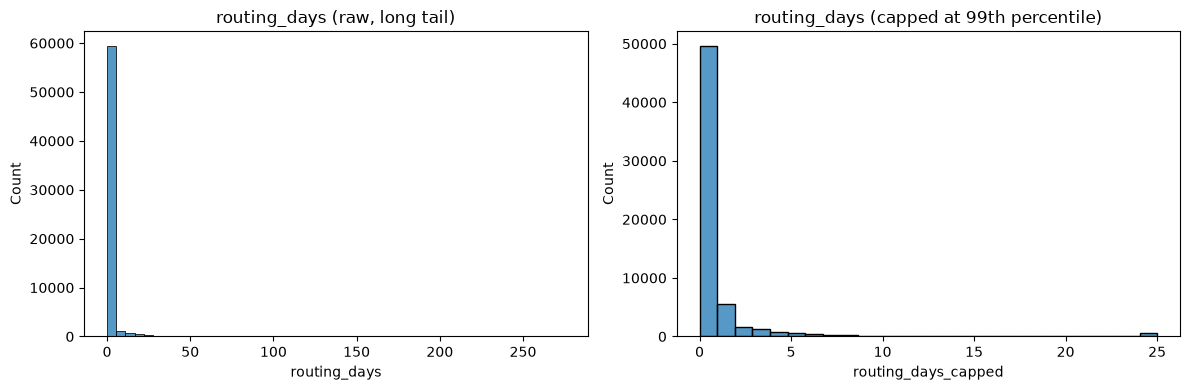

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['routing_days'], bins=50, ax=ax[0])
ax[0].set_title('routing_days (raw, long tail)')
sns.histplot(df['routing_days_capped'], bins=26, ax=ax[1])
ax[1].set_title('routing_days (capped at 99th percentile)')
plt.tight_layout()
plt.show()

In [20]:
# cleaned data
df.head(5)

,complaint_id,submitted_via,date_submitted,date_received,state,product,sub_product,issue,sub_issue,public_response,...,routing_days,year,quarter,month,is_closed,got_relief,got_monetary,routing_band,late_routing,routing_days_capped
0,4848023,Referral,2021-10-24,2021-10-27,NY,Mortgage,Conventional home mortgage,Applying for a mortgage or refinancing an exis...,Not specified,Company has responded to the consumer and the ...,...,3,2021,4,10,1,0,0,1-7 days,0,3
1,3621464,Web,2020-04-24,2020-04-24,FL,"Money transfer, virtual currency, or money ser...",Refund anticipation check,Lost or stolen check,Not specified,Company has responded to the consumer and the ...,...,0,2020,2,4,1,1,1,Same day,0,0
2,5818349,Web,2022-07-27,2022-07-27,CA,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Account information incorrect,Company has responded to the consumer and the ...,...,0,2022,3,7,1,0,0,Same day,0,0
3,7233015,Referral,2023-07-10,2023-07-11,CA,Credit card or prepaid card,General-purpose prepaid card,Problem getting a card or closing an account,"Trouble getting, activating, or registering a ...",Not specified,...,1,2023,3,7,0,0,0,1-7 days,0,1
4,5820224,Referral,2022-07-27,2022-07-28,VA,Credit card or prepaid card,General-purpose credit card or charge card,Closing your account,Company closed your account,Company has responded to the consumer and the ...,...,1,2022,3,7,1,0,0,1-7 days,0,1


In [21]:
df.shape

(62516, 23)

In [22]:
df.columns

Index(['complaint_id', 'submitted_via', 'date_submitted', 'date_received',
       'state', 'product', 'sub_product', 'issue', 'sub_issue',
       'public_response', 'company_response', 'timely_response', 'is_timely',
       'routing_days', 'year', 'quarter', 'month', 'is_closed', 'got_relief',
       'got_monetary', 'routing_band', 'late_routing', 'routing_days_capped'],
      dtype='str')

In [28]:
df.to_excel(r"C:\Users\sumit\Downloads\Customer_Complaints\Consumer_Complaints cleaned data.xlsx",index=False)

In [23]:
print("data successfully saved!")

data successfully saved!


###  3.Exploratory Data Analysis
#### Univariate analysis

##### VISUAL -1 COMPLAINTS BY PRODUCT 

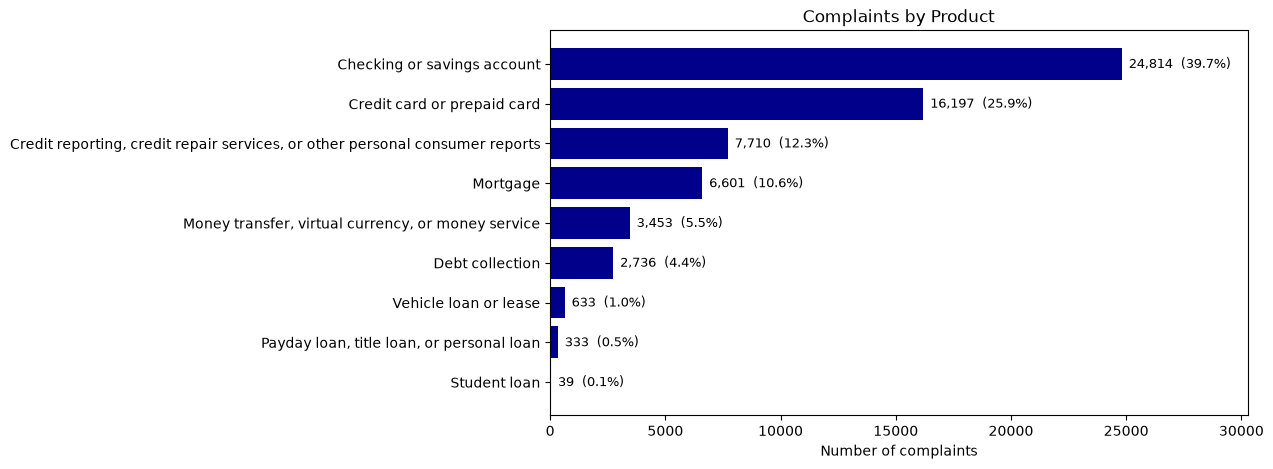

In [19]:
prod_counts = df["product"].value_counts()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(prod_counts.index[::-1], prod_counts.values[::-1], color="DarkBlue")
for b, v in zip(bars, prod_counts.values[::-1]):
    ax.text(v + 300, b.get_y() + b.get_height()/2, f"{v:,}  ({v/len(df):.1%})", va="center", fontsize=9)
ax.set_title("Complaints by Product")
ax.set_xlabel("Number of complaints"); ax.set_ylabel("")
ax.set_xlim(0, prod_counts.max() * 1.22)
plt.show()

#### observations Visual 1 – Complaints by product
##### *Pull the numbers with df['product'].value_counts(normalize=True).head(3).
##### *Note which product dominates and what share the top 3 hold. Mention the long tail (Student loan appears only in 2022 in your pivot).

#### VISUAL-2 SUBMISSION CHANNEL USAGE RATING

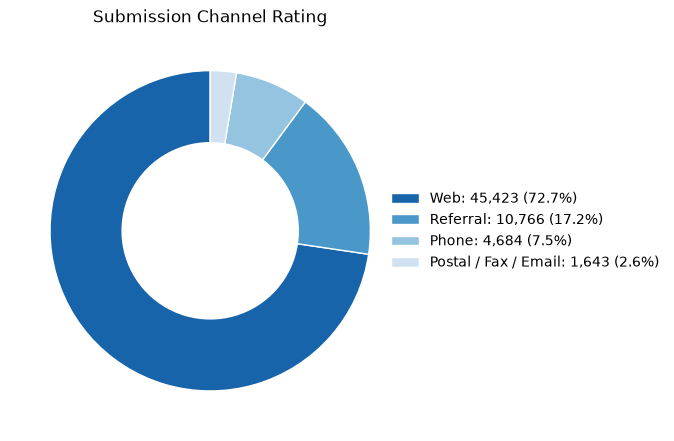

In [20]:
fig, ax = plt.subplots(figsize=(14, 5.2))
ch = df["submitted_via"].value_counts()
vals = pd.concat([ch[["Web", "Referral", "Phone"]], pd.Series({"Postal / Fax / Email": ch.drop(["Web", "Referral", "Phone"]).sum()})])
colors = sns.color_palette("Blues_r", len(vals))
ax.pie(vals, startangle=90, colors=colors, wedgeprops=dict(width=0.45, edgecolor="white"))
ax.legend([f"{k}: {v:,} ({v/vals.sum():.1%})" for k, v in vals.items()], loc="center left",
               bbox_to_anchor=(0.92, 0.5), frameon=False)
ax.set_title("Submission Channel Rating")
plt.show()

#### observations Visual 2 – Submission channel (donut)
##### *Web dominates at 72.7% (45,423), followed by Referral at 17.2% and Phone at 7.5%.
##### *Postal mail, fax, email and web referral together are only 2.6%, so paper channels are nearly irrelevant.
##### *Complaints are overwhelmingly digital, which fits the fast routing seen above.

####  VISUAL-3 COMPANY RESPONSE TO CONSUMERS

Text(0.5, 1.0, 'Company Response to Consumer')

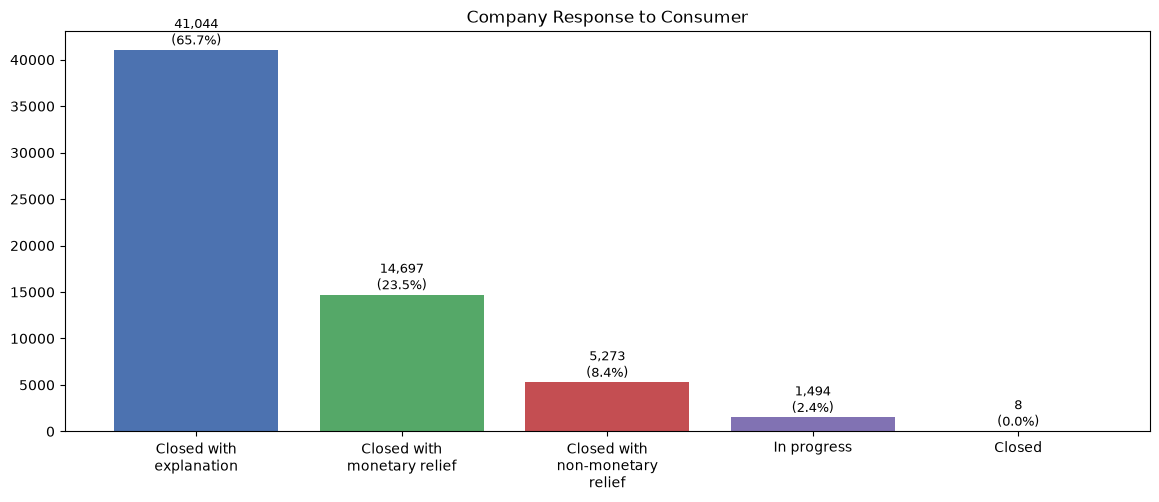

In [21]:
fig, axes = plt.subplots(figsize=(14, 5.2))
resp = df['company_response'].value_counts()

LABELS = {
    'Closed with explanation': 'Closed with\nexplanation',
    'Closed with monetary relief': 'Closed with\nmonetary relief',
    'Closed with non-monetary relief': 'Closed with\nnon-monetary\nrelief',
    'In progress': 'In progress',
    'Closed': 'Closed'}


# 1. Define the missing color mapping
OUTCOME_COLORS = {
    'Closed with explanation': '#4C72B0',
    'Closed with monetary relief': '#55A868',
    'Closed with non-monetary relief': '#C44E52',
    'In progress': '#8172B3',
    'Closed': '#CCB974'}

axes.bar(
    [LABELS[k] for k in resp.index], 
    resp.values, 
    color=[OUTCOME_COLORS[k] for k in resp.index])

# 2. Change 'ax' to 'axes' to match line 1
for i, v in enumerate(resp.values):
    axes.text(i, v + 600, f"{v:,}\n({v/len(df):.1%})", ha='center', fontsize=9)

axes.set_title('Company Response to Consumer')

#### observations Visual 3 – Company response to consumer
##### *65.7% are closed with explanation only, 23.5% with monetary relief, and 8.4% with non-monetary relief.
##### *2.4% are still in progress, and "Closed" (no detail) is just 8 cases.
##### *About two-thirds of consumers get an explanation but no remedy.

#### Visual 4 – Top 15 states by Number complaints

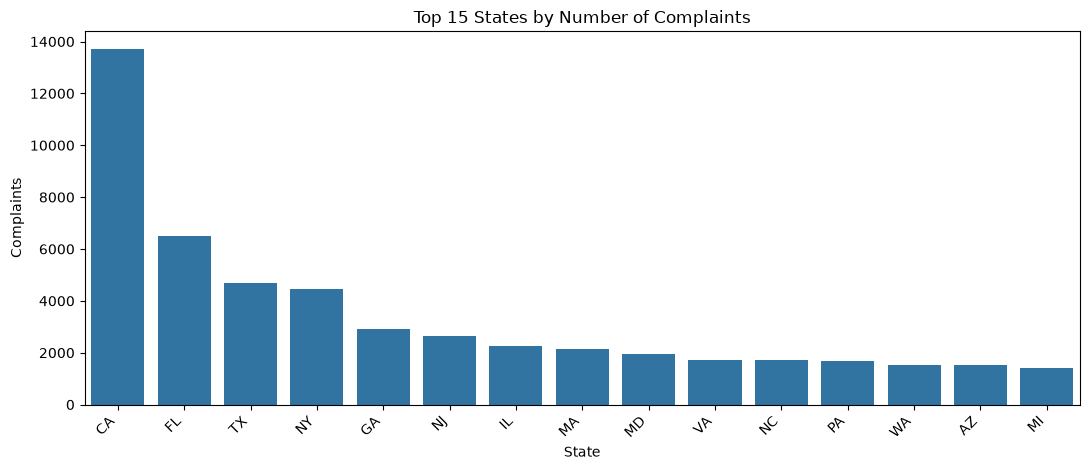

In [23]:
BLUE = '#1f77b4'  # define the color before using it

state_counts = df["state"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.barplot(x=state_counts.index.astype(str), y=state_counts.values, color=BLUE, ax=ax)
ax.set_title("Top 15 States by Number of Complaints")
ax.set_xlabel("State"); ax.set_ylabel("Complaints")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### observations Visual 4 – Top 15 states
##### *Complaint volume tracks population, so state rankings partly reflect size. Normalise per capita before drawing conclusions about "worst" states.
##### *Code fix: BLUE is defined after it is used, and plt.show() sits inside the loop. Move both outside the loop.

##### VISUAL-5 -TOP ISSUES

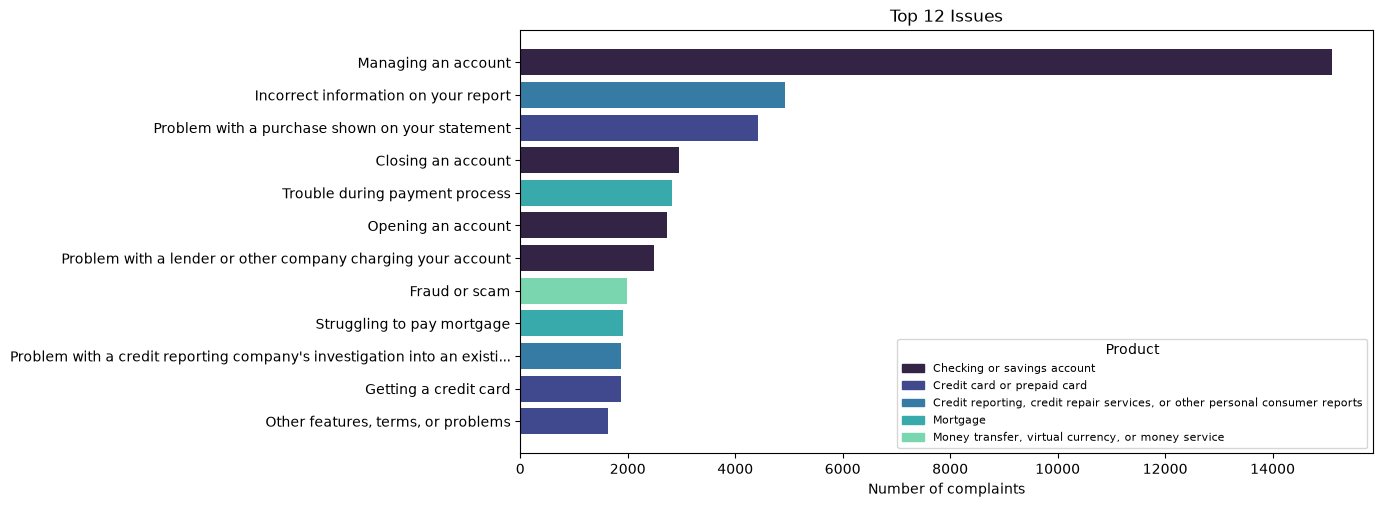

In [66]:
top_issues = df["issue"].value_counts().head(12).index
iss = (df[df["issue"].isin(top_issues)].groupby(["issue", "product"], observed=True).size()
         .reset_index(name="n"))
# dominant product for each issue (for colour) + total
dom = iss.sort_values("n", ascending=False).drop_duplicates("issue").set_index("issue")["product"]
tot = df["issue"].value_counts().head(12)

fig, ax = plt.subplots(figsize=(11, 5.5))
pal = dict(zip(dom.unique(), sns.color_palette("mako", dom.nunique()))) 
ax.barh([i[:70] + ("..." if len(i) > 70 else "") for i in tot.index[::-1]], tot.values[::-1],
        color=[pal[dom[i]] for i in tot.index[::-1]])
ax.set_title("Top 12 Issues")
ax.set_xlabel("Number of complaints"); ax.set_ylabel("")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in pal.values()], labels=list(pal.keys()),
          title="Product", loc="lower right", fontsize=8)
plt.show()

#### observations Visual 5 – Top 12 issues
##### *Pull the numbers with df['issue'].value_counts().head(12).
##### *State the top issue and its share, and which product it belongs to (the colour in the chart).
##### *The 76 distinct issues map onto only 9 products, so a few issues likely account for a large share.

##### Visual 6 – Seasonality heatmap

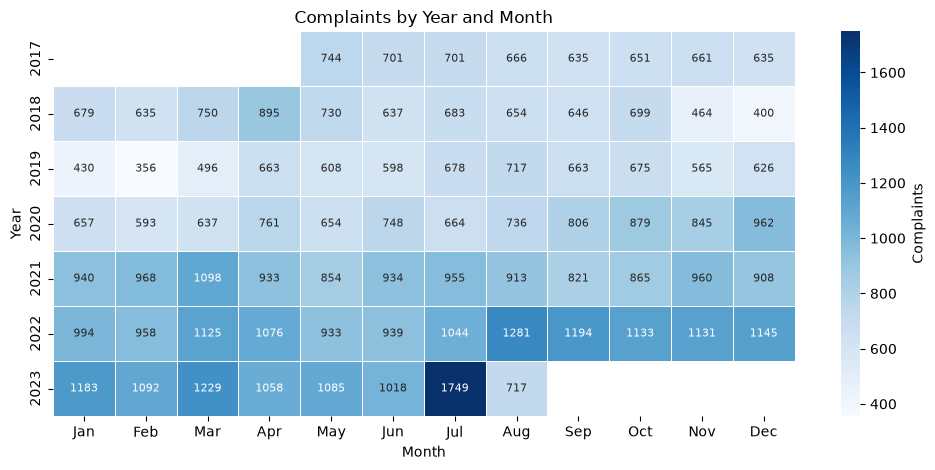

In [45]:
pivot_ym = df.pivot_table(index="year", columns="month", values="complaint_id", aggfunc="count")
pivot_ym.columns = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(pivot_ym, annot=True, fmt=".0f", cmap="Blues", linewidths=.5, ax=ax,
            cbar_kws={"label": "Complaints"}, annot_kws={"size": 8})
ax.set_title("Complaints by Year and Month")
ax.set_xlabel("Month"); ax.set_ylabel("Year")

plt.tight_layout()
plt.show()

##### observations Visuals  7 -complaints by year heatmap
##### *Mention the overall trend: the 3-month rolling mean smooths noise, so call out any spikes.
##### *Note any seasonality. Also say that the first and last years are partial.

#### Bivariate analysis-(Relate two variables at a time)

#### Visual 7 – Product mix over time 

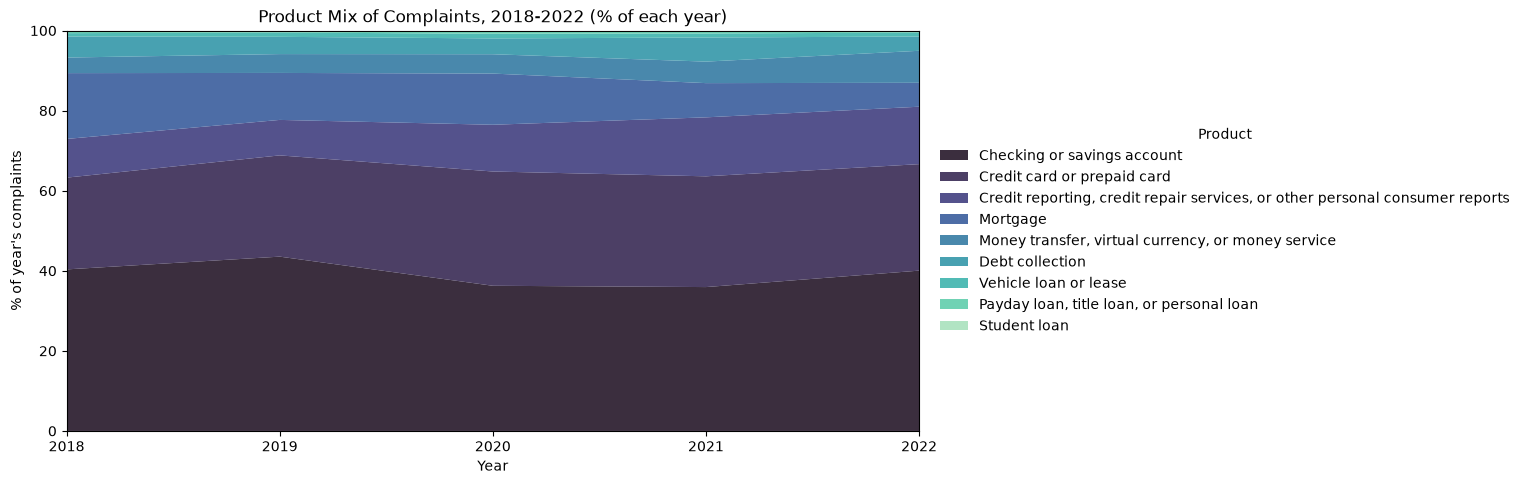

In [65]:
mix = (df[df["year"].between(2018, 2022)]
       .pivot_table(index="year", columns="product", values="complaint_id", aggfunc="count", fill_value=0))
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
order = mix.sum().sort_values(ascending=False).index
mix_pct = mix_pct[order]

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.stackplot(mix_pct.index, mix_pct.T.values, labels=mix_pct.columns, colors=sns.color_palette("mako", len(order)), alpha=.9)
ax.set_title("Product Mix of Complaints, 2018-2022 (% of each year)")
ax.set_xlabel("Year"); ax.set_ylabel("% of year's complaints"); ax.set_xticks(mix_pct.index)
ax.set_xlim(2018, 2022); ax.set_ylim(0, 100)
ax.legend(loc="center left", bbox_to_anchor=(1.01, .5), title="Product", frameon=False)
plt.show()

#### observations Visual 7 – Product mix over time (2018–2022)
##### *Your pivot shows Mortgage and Credit card shifting most, so check whether their shares in the stacked chart rise or fall.
##### *Comment on whether the mix is stable or changing, since the stack shows share and not volume.

#### Visual 8 – Outcome by product 

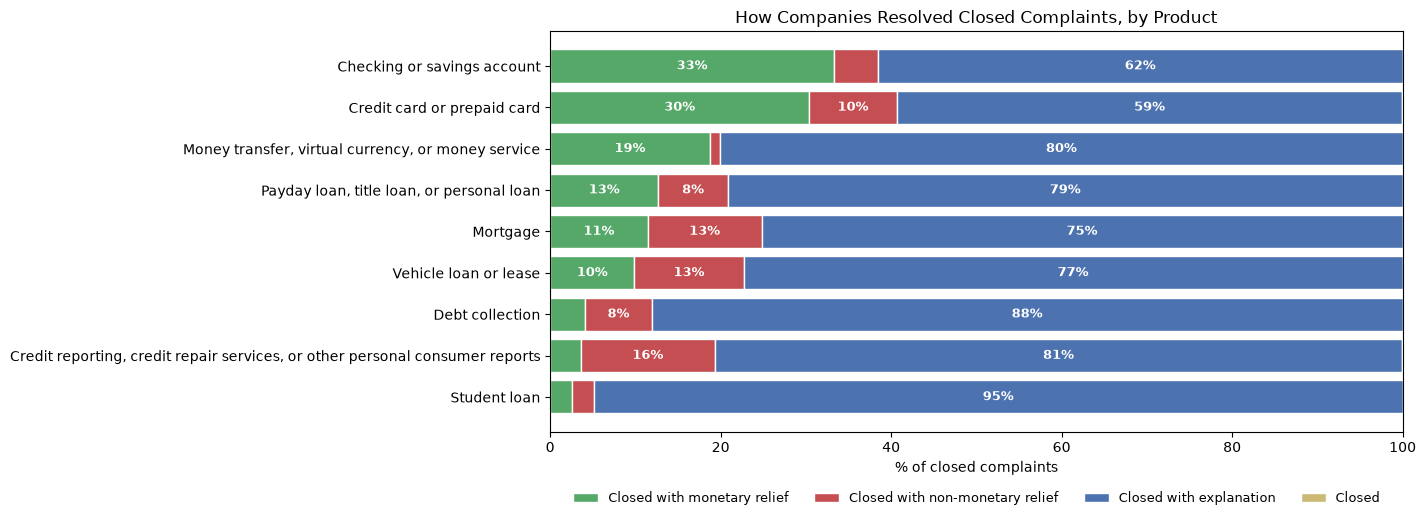

In [32]:
closed = df[df["company_response"] != "In progress"].copy()
closed["got_relief"] = closed["company_response"].isin(
    ["Closed with monetary relief", "Closed with non-monetary relief"]
).astype(int)
closed["got_monetary"] = (closed["company_response"] == "Closed with monetary relief").astype(int)
ct = pd.crosstab(closed["product"], closed["company_response"], normalize="index") * 100
ct = ct[["Closed with monetary relief", "Closed with non-monetary relief", "Closed with explanation", "Closed"]]
ct = ct.sort_values("Closed with monetary relief")

fig, ax = plt.subplots(figsize=(11, 5.2))
left = np.zeros(len(ct))
for col in ct.columns:
    ax.barh(ct.index, ct[col], left=left, color=OUTCOME_COLORS[col], label=col, edgecolor="white")
    for y, (l, w) in enumerate(zip(left, ct[col])):
        if w >= 6: ax.text(l + w/2, y, f"{w:.0f}%", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    left += ct[col].values
ax.set_title("How Companies Resolved Closed Complaints, by Product")
ax.set_xlabel("% of closed complaints"); ax.set_ylabel(""); ax.set_xlim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=4, frameon=False, fontsize=9)
plt.show()

#### observations Visual 8 – Outcome by product
##### *Use ct.round(1) to pick the products with the highest and lowest monetary-relief share.
##### *The pivot below supports a point about checking and credit cards giving relief more often than credit reporting or debt collection.

####  Multivariate analysis-(Three or more variables at once)

##### Visual 9 – Relief rate heatmap

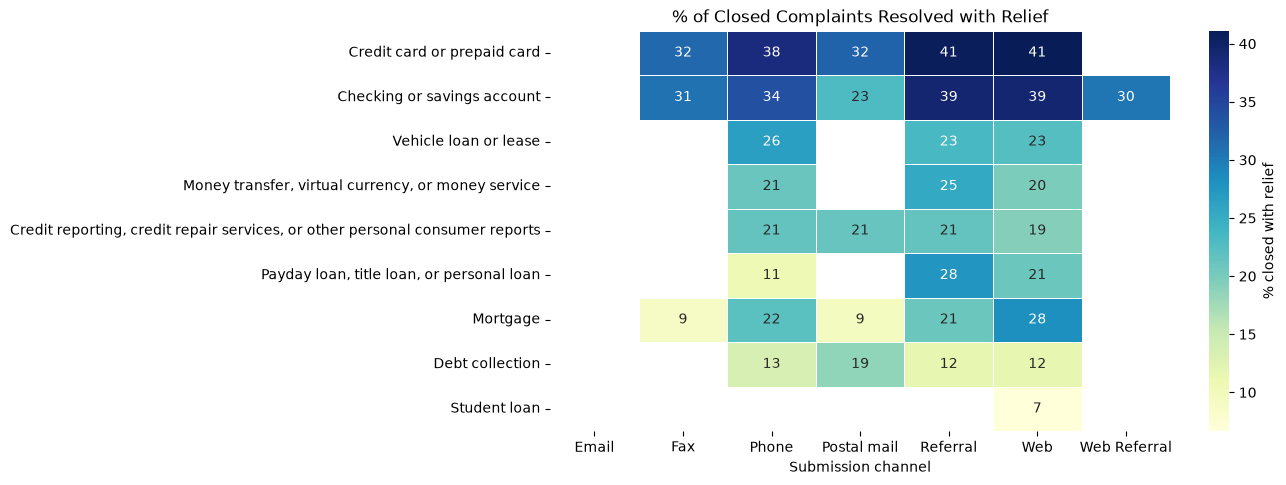

In [34]:
hm = closed.pivot_table(index="product", columns="submitted_via", values="got_relief", aggfunc="mean") * 100
cnt = closed.pivot_table(index="product", columns="submitted_via", values="got_relief", aggfunc="size")
hm = hm.where(cnt >= 30)
hm = hm.loc[hm.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 5.2))
sns.heatmap(hm, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=.5, ax=ax, cbar_kws={"label": "% closed with relief"},
            mask=hm.isna())
ax.set_title("% of Closed Complaints Resolved with Relief")
ax.set_xlabel("Submission channel"); ax.set_ylabel("")
plt.show()

#### observations Visual 9 – Relief % by product × channel
##### Cells with fewer than 30 cases are masked, so blank cells mean "too little data", not 0%.
##### Look for the channel with the highest relief rate and any product where channel matters. Referral and Web can differ a lot because referral complaints are pre-vetted by regulators.

##### Visual 10 – State-level scatter: volume vs relief rate

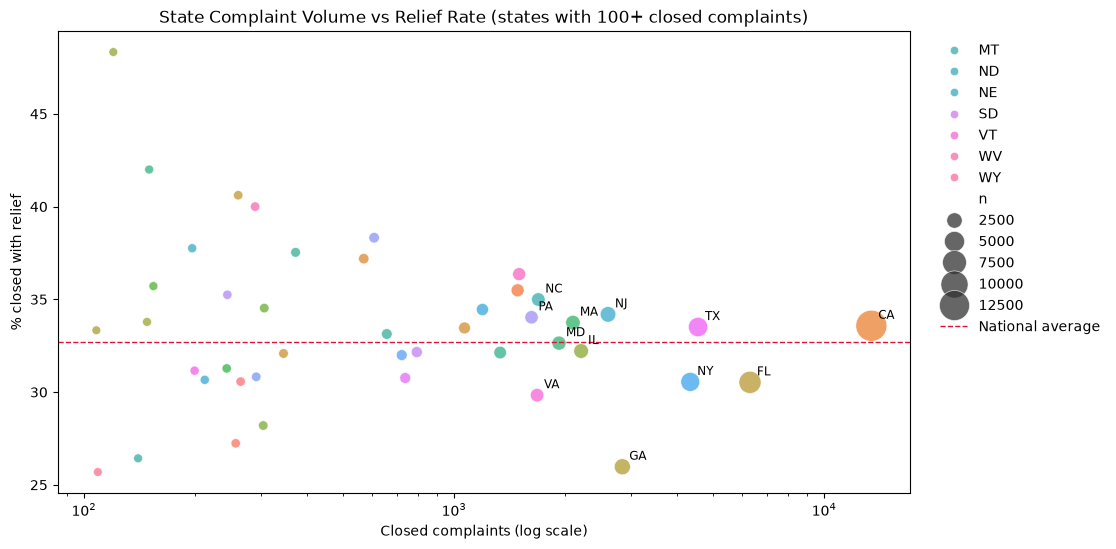

In [49]:
st = (closed.groupby(["state"], observed=True)
      .agg(n=("complaint_id", "size"), relief=("got_relief", "mean")).reset_index())
st = st[st["n"] >= 100]
st["relief"] *= 100

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=st, x="n", y="relief", hue="state", size="n", sizes=(40, 500), alpha=.75, ax=ax, legend="brief")

for _, r in st.sort_values("n", ascending=False).head(12).iterrows():
    ax.annotate(r["state"], (r["n"], r["relief"]), xytext=(5, 5), textcoords="offset points", fontsize=8.5)

ax.axhline(closed["got_relief"].mean() * 100, color="crimson", ls="--", lw=1, label="National average")
ax.set_xscale("log")
ax.set_title("State Complaint Volume vs Relief Rate (states with 100+ closed complaints)")
ax.set_xlabel("Closed complaints (log scale)")
ax.set_ylabel("% closed with relief")

# Keep ONLY "National average" and the bubble size ("n") items in the legend
h, l = ax.get_legend_handles_labels()
state_codes = set(st["state"].astype(str)) | {"state"}
keep = [(handle, label) for handle, label in zip(h, l) if label not in state_codes]
ax.legend(*zip(*keep), bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)

plt.show()

#### observations Visual 10 – State volume vs relief rate
##### *The x-axis is log scale, so bubble position shows volume and the red dashed line is the 32.7% national average.
##### *Call out states with high volume but below-average relief, and low-volume states far from the line (small samples, so likely noise).
##### *Only states with 100+ closed complaints are shown.

#### Pivot tables & statistical summaries

##### A pivot table for the report: complaints, relief rate and timely rate per product and year, with a trend test for timeliness over the years.

In [46]:
pv = pd.pivot_table(closed[closed["year"].between(2018, 2022)], index="product", columns="year",
                    values="got_relief", aggfunc="mean") * 100
pv.round(1)

year,2018,2019,2020,2021,2022
product,,,,,
Checking or savings account,42.5,38.5,37.9,38.6,37.7
Credit card or prepaid card,38.0,37.9,36.2,38.0,48.4
"Credit reporting, credit repair services, or other personal consumer reports",25.0,28.1,20.4,10.2,19.9
Debt collection,17.1,13.1,12.2,9.4,9.7
"Money transfer, virtual currency, or money service",19.3,18.0,20.8,23.9,17.3
Mortgage,15.9,18.8,40.0,35.4,28.4
"Payday loan, title loan, or personal loan",22.5,12.9,21.5,19.7,23.8
Student loan,0.0,0.0,0.0,0.0,33.3
Vehicle loan or lease,35.4,15.8,29.5,26.5,13.4


#### observations Pivot table – relief % by product and year
##### *Credit card or prepaid card jumps to 48.4% in 2022, the highest value in the table.
##### *Mortgage rises from 15.9% (2018) to 40.0% (2020), then eases to 28.4%.
##### *Debt collection steadily declines (17.1% to 9.7%), and Credit reporting dips to 10.2% in 2021.
##### *Student loan shows 0% until 33.3% in 2022. This is almost certainly tiny counts, so exclude or footnote it.